<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/11-transformer-text-classification/transformer_based_text_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Project introduction
# Project 11: Transformer-Based Text Classification

#### Objective
Fine-tune a pretrained DistilBERT transformer for multiclass news
classification using the AG News dataset.

#### Dataset
AG News: 4 categories
- World
- Sports
- Business
- Sci/Tech

#### Model
distilbert/distilbert-base-uncased

#### Main Evaluation Metric
Macro-F1

#### Additional Evaluation
- Accuracy
- Macro Precision
- Macro Recall
- Per-class Precision, Recall and F1
- Confusion Matrix
- Misclassification Analysis

## Workflow
1. Load and explore dataset
2. Split training data into train and validation
3. Tokenize text
4. Fine-tune DistilBERT
5. Select best checkpoint using validation Macro-F1
6. Evaluate on official test set
7. Perform error analysis
8. Export results and trained model

### Cell 2 - Install dependencies

In [ ]:

!pip install -q --upgrade pip
!pip install -q transformers==4.46.3 datasets==2.21.0 accelerate==0.34.2 scikit-learn matplotlib seaborn pandas numpy


### Cell 3 - Import libraries and configure environment

In [ ]:
import os
import json
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from IPython.display import display

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()

OUTPUT_DIR = "project11_outputs"
CHECKPOINT_DIR = os.path.join(OUTPUT_DIR, "best_checkpoint")

os.makedirs(OUTPUT_DIR, exist_ok=True)

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 128
BATCH_SIZE = 16
LEARNING_RATE = 2e-5
EPOCHS = 3

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: GPU unavailable. Training may be slow.")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


### Cell 4 - Load AG News dataset

In [ ]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("\nDataset splits:")
for split in dataset:
    print(split, len(dataset[split]))

label_names = dataset["train"].features["label"].names

print("\nClass names:", label_names)
print("\nSample record:")
print(dataset["train"][0])

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Dataset splits:
train 120000
test 7600

Class names: ['World', 'Sports', 'Business', 'Sci/Tech']

Sample record:
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


### Cell 5 - Dataset exploration

Training samples: 120000
Official test samples: 7600

Training class distribution:


,count,percentage
label,,
World,30000,25.0
Sports,30000,25.0
Business,30000,25.0
Sci/Tech,30000,25.0


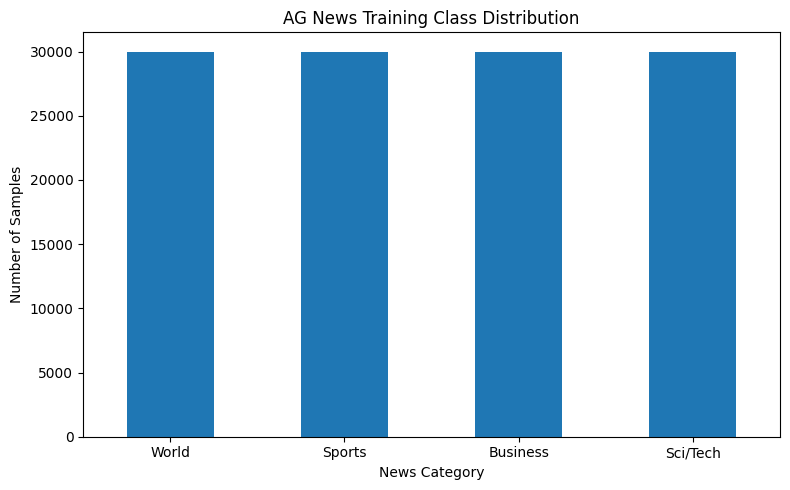


Example news records:


,text,label
0,Wall St. Bears Claw Back Into the Black (Reute...,2
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2
3,Iraq Halts Oil Exports from Main Southern Pipe...,2
4,"Oil prices soar to all-time record, posing new...",2


In [ ]:
train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

print("Training samples:", len(train_df))
print("Official test samples:", len(test_df))

print("\nTraining class distribution:")
train_distribution = (
    train_df["label"]
    .value_counts()
    .sort_index()
    .rename(index=dict(enumerate(label_names)))
    .to_frame("count")
)

train_distribution["percentage"] = (
    train_distribution["count"] / len(train_df) * 100
)

display(train_distribution)

plt.figure(figsize=(8, 5))
train_distribution["count"].plot(kind="bar")
plt.title("AG News Training Class Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "class_distribution.png"),
    dpi=150
)
plt.show()

train_distribution.to_csv(
    os.path.join(OUTPUT_DIR, "class_distribution.csv")
)

print("\nExample news records:")
display(train_df[["text", "label"]].head())

### Cell 6 - Train-validation split

In [ ]:
split_dataset = dataset["train"].train_test_split(
    test_size=0.10,
    seed=SEED,
    stratify_by_column="label"
)

train_dataset = split_dataset["train"]
validation_dataset = split_dataset["test"]
test_dataset = dataset["test"]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))
print("Official test samples:", len(test_dataset))

print("\nTraining distribution:")
print(train_dataset.features["label"].names)
print(train_dataset.to_pandas()["label"].value_counts().sort_index())

print("\nValidation distribution:")
print(validation_dataset.to_pandas()["label"].value_counts().sort_index())

print("\nTest distribution:")
print(test_dataset.to_pandas()["label"].value_counts().sort_index())

Training samples: 108000
Validation samples: 12000
Official test samples: 7600

Training distribution:
['World', 'Sports', 'Business', 'Sci/Tech']
label
0    27000
1    27000
2    27000
3    27000
Name: count, dtype: int64

Validation distribution:
label
0    3000
1    3000
2    3000
3    3000
Name: count, dtype: int64

Test distribution:
label
0    1900
1    1900
2    1900
3    1900
Name: count, dtype: int64


### Cell 7 -  Load pretrained tokenizer

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")
print("Model checkpoint:", MODEL_NAME)
print("Maximum sequence length:", MAX_LENGTH)

sample_text = train_dataset[0]["text"]

sample_tokens = tokenizer(
    sample_text,
    truncation=True,
    max_length=MAX_LENGTH
)

print("\nSample text:")
print(sample_text)

print("\nToken IDs:")
print(sample_tokens["input_ids"][:30])

print("\nDecoded tokens:")
print(tokenizer.decode(sample_tokens["input_ids"]))

Tokenizer loaded successfully.
Model checkpoint: distilbert/distilbert-base-uncased
Maximum sequence length: 128

Sample text:
Three tied for lead at Southern Farm Bureau Classic John Senden carded a pair of eagles, Harrison Frazar shot a 31 on the front nine and Glen Day recorded seven birdies to finish Thursday #39;s first round of the 

Token IDs:
[101, 2093, 5079, 2005, 2599, 2012, 2670, 3888, 4879, 4438, 2198, 4604, 2368, 4003, 2098, 1037, 3940, 1997, 8125, 1010, 6676, 25312, 9057, 2915, 1037, 2861, 2006, 1996, 2392, 3157]

Decoded tokens:
[CLS] three tied for lead at southern farm bureau classic john senden carded a pair of eagles, harrison frazar shot a 31 on the front nine and glen day recorded seven birdies to finish thursday # 39 ; s first round of the [SEP]


Cell 8 - Tokenize all datasets

In [ ]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )

tokenized_train = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_validation = validation_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

tokenized_test = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

print("Tokenization completed.")

print("Train:", len(tokenized_train))
print("Validation:", len(tokenized_validation))
print("Test:", len(tokenized_test))

print("\nTokenized sample:")
print(tokenized_train[0].keys())

Tokenization completed.
Train: 108000
Validation: 12000
Test: 7600

Tokenized sample:
dict_keys(['label', 'input_ids', 'token_type_ids', 'attention_mask'])


### Cell 9 - Load pretrained DistilBERT

In [ ]:
num_labels = len(label_names)

id2label = {
    i: label for i, label in enumerate(label_names)
}

label2id = {
    label: i for i, label in enumerate(label_names)
}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print(model.config)
print("\nModel loaded successfully.")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertConfig {
  "activation": "gelu",
  "architectures": [
    "DistilBertForMaskedLM"
  ],
  "attention_dropout": 0.1,
  "bos_token_id": null,
  "dim": 768,
  "dropout": 0.1,
  "dtype": "float32",
  "eos_token_id": null,
  "hidden_dim": 3072,
  "id2label": {
    "0": "World",
    "1": "Sports",
    "2": "Business",
    "3": "Sci/Tech"
  },
  "initializer_range": 0.02,
  "label2id": {
    "Business": 2,
    "Sci/Tech": 3,
    "Sports": 1,
    "World": 0
  },
  "max_position_embeddings": 512,
  "model_type": "distilbert",
  "n_heads": 12,
  "n_layers": 6,
  "pad_token_id": 0,
  "qa_dropout": 0.1,
  "seq_classif_dropout": 0.2,
  "sinusoidal_pos_embds": false,
  "tie_weights_": true,
  "tie_word_embeddings": true,
  "transformers_version": "5.20.2",
  "vocab_size": 30522
}


Model loaded successfully.


Cell 10 - Data collator and evaluation metrics

In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    return {
        "accuracy": float(accuracy),
        "macro_precision": float(precision),
        "macro_recall": float(recall),
        "macro_f1": float(f1)
    }

print("Evaluation metrics configured.")
print("Primary model-selection metric: Macro-F1")

Evaluation metrics configured.
Primary model-selection metric: Macro-F1


### Cell 11 - Training configuration

In [ ]:
training_args = TrainingArguments(
    output_dir=CHECKPOINT_DIR,

    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,

    learning_rate=LEARNING_RATE,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,

    save_total_limit=2,

    fp16=torch.cuda.is_available(),

    seed=SEED,
    data_seed=SEED,

    report_to="none"
)

# Set warmup_ratio dynamically to avoid TypeError during initialization
training_args.warmup_ratio = 0.1

print("Training configuration:")
print(training_args)

Training configuration:
TrainingArguments(
accelerator_config={'split_batches': False, 'dispatch_batches': None, 'even_batches': True, 'use_seedable_sampler': True, 'non_blocking': False, 'gradient_accumulation_kwargs': None, 'use_configured_state': False},
adam_beta1=0.9,
adam_beta2=0.999,
adam_epsilon=1e-08,
auto_find_batch_size=False,
average_tokens_across_devices=True,
batch_eval_metrics=False,
bf16=False,
bf16_full_eval=False,
data_seed=42,
dataloader_drop_last=False,
dataloader_in_order=True,
dataloader_multiprocessing_context=None,
dataloader_num_workers=0,
dataloader_persistent_workers=False,
dataloader_pin_memory=True,
dataloader_prefetch_factor=None,
ddp_backend=None,
ddp_broadcast_buffers=None,
ddp_bucket_cap_mb=None,
ddp_find_unused_parameters=None,
ddp_static_graph=None,
ddp_timeout=1800,
debug=[],
deepspeed=None,
disable_tqdm=False,
do_eval=True,
do_predict=False,
do_train=False,
enable_jit_checkpoint=False,
eval_accumulation_steps=None,
eval_delay=0,
eval_do_concat_batch

### Cell 12 - Initialize Trainer

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=tokenized_train,
    eval_dataset=tokenized_validation,

    processing_class=tokenizer,
    data_collator=data_collator,

    compute_metrics=compute_metrics,

    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=2
        )
    ]
)

print("Trainer initialized successfully.")

Trainer initialized successfully.


### Cell 13 - Fine-tune DistilBERT

In [ ]:
train_result = trainer.train()

print("\nTraining completed.")

print("\nTraining metrics:")
print(train_result.metrics)

print("\nBest checkpoint:")
print(trainer.state.best_model_checkpoint)

print("\nBest validation metric:")
print(trainer.state.best_metric)

Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1
1,0.232208,0.183216,0.941667,0.942522,0.941667,0.941759
2,0.140549,0.207243,0.943667,0.944622,0.943667,0.943687
3,0.094869,0.226819,0.945500,0.945809,0.945500,0.945551


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Training completed.

Training metrics:
{'train_runtime': 1035.3436, 'train_samples_per_second': 312.94, 'train_steps_per_second': 19.559, 'total_flos': 7707567598762752.0, 'train_loss': 0.15587522605613427, 'epoch': 3.0}

Best checkpoint:
project11_outputs/best_checkpoint/checkpoint-20250

Best validation metric:
0.9455511940729968


### Cell 14 - Training history

Training history:


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_macro_precision,eval_macro_recall,eval_macro_f1,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,0.232208,6.291205,1.333432e-05,1.0,6750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,1.0,6750,0.183216,0.941667,0.942522,0.941667,0.941759,9.7606,1229.438,76.840,NaN,NaN,NaN,NaN,NaN
2,0.140549,5.325376,6.667654e-06,2.0,13500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,2.0,13500,0.207243,0.943667,0.944622,0.943667,0.943687,9.7314,1233.120,77.070,NaN,NaN,NaN,NaN,NaN
4,0.094869,7.421927,9.876543e-10,3.0,20250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,3.0,20250,0.226819,0.945500,0.945809,0.945500,0.945551,9.6730,1240.565,77.535,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,3.0,20250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1035.3436,312.94,19.559,7.707568e+15,0.155875


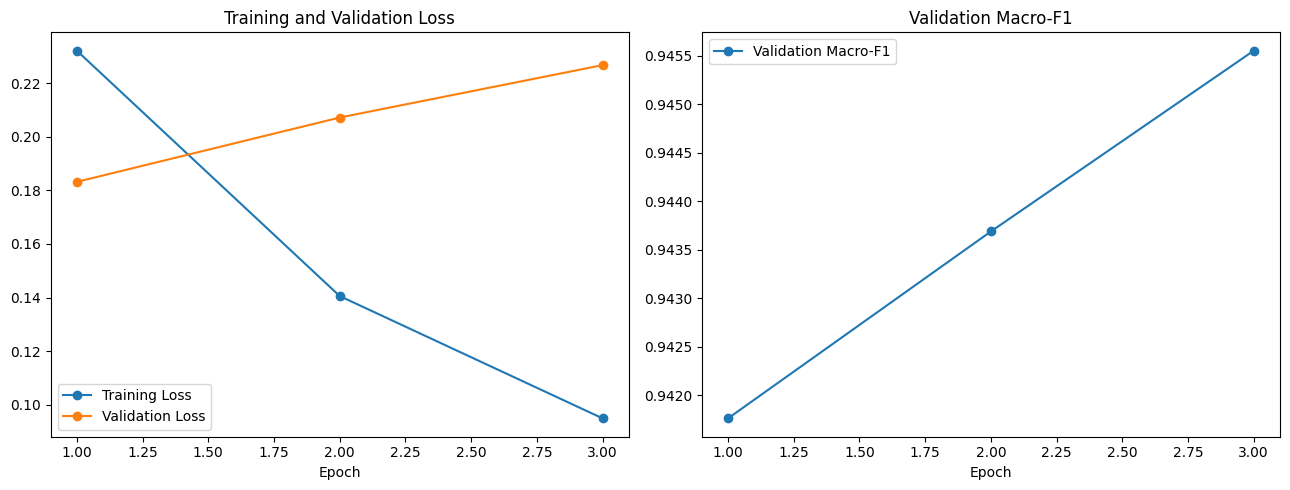

In [ ]:
history = pd.DataFrame(trainer.state.log_history)

print("Training history:")
display(history)

history.to_csv(
    os.path.join(OUTPUT_DIR, "training_history.csv"),
    index=False
)

train_logs = history[
    history["loss"].notna()
] if "loss" in history.columns else pd.DataFrame()

eval_logs = history[
    history["eval_loss"].notna()
] if "eval_loss" in history.columns else pd.DataFrame()

if not train_logs.empty and not eval_logs.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].plot(
        train_logs["epoch"],
        train_logs["loss"],
        marker="o",
        label="Training Loss"
    )
    axes[0].plot(
        eval_logs["epoch"],
        eval_logs["eval_loss"],
        marker="o",
        label="Validation Loss"
    )
    axes[0].set_title("Training and Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(
        eval_logs["epoch"],
        eval_logs["eval_macro_f1"],
        marker="o",
        label="Validation Macro-F1"
    )
    axes[1].set_title("Validation Macro-F1")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, "training_curves.png"),
        dpi=150
    )
    plt.show()
else:
    print("Training or evaluation logs unavailable for plotting.")

### Cell 15 - Official test evaluation

In [ ]:
test_results = trainer.evaluate(
    eval_dataset=tokenized_test,
    metric_key_prefix="test"
)

print("Official test results:")
for key, value in test_results.items():
    print(f"{key}: {value}")

[transformers] early stopping required metric_for_best_model, but did not find eval_macro_f1 so early stopping is disabled


Training Loss,Validation Loss,Epoch,Accuracy,Macro Precision,Macro Recall,Macro F1
0.094869,0.224059,3,0.945132,0.945224,0.945132,0.945166


Official test results:
test_loss: 0.22405922412872314
test_accuracy: 0.9451315789473684
test_macro_precision: 0.9452236155146334
test_macro_recall: 0.9451315789473684
test_macro_f1: 0.9451657964620934


### Cell 16 - Test predictions and classification report

In [ ]:
prediction_output = trainer.predict(tokenized_test)

test_logits = prediction_output.predictions
y_true = prediction_output.label_ids

y_pred = np.argmax(test_logits, axis=1)

report_dict = classification_report(
    y_true,
    y_pred,
    target_names=label_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

print("Classification report:")
display(report_df)

report_df.to_csv(
    os.path.join(OUTPUT_DIR, "classification_report.csv")
)

metrics_dict = {
    key: float(value)
    for key, value in test_results.items()
    if isinstance(value, (int, float, np.integer, np.floating))
}

with open(
    os.path.join(OUTPUT_DIR, "test_metrics.json"),
    "w"
) as f:
    json.dump(metrics_dict, f, indent=4)

Classification report:


,precision,recall,f1-score,support
World,0.959767,0.954211,0.956981,1900.000000
Sports,0.987876,0.986316,0.987095,1900.000000
Business,0.916975,0.912632,0.914798,1900.000000
Sci/Tech,0.916277,0.927368,0.921789,1900.000000
accuracy,0.945132,0.945132,0.945132,0.945132
macro avg,0.945224,0.945132,0.945166,7600.000000
weighted avg,0.945224,0.945132,0.945166,7600.000000


### Cell 17 - Confusion matrix

Confusion Matrix:


,World,Sports,Business,Sci/Tech
World,1813,11,46,30
Sports,12,1874,7,7
Business,36,6,1734,124
Sci/Tech,28,6,104,1762


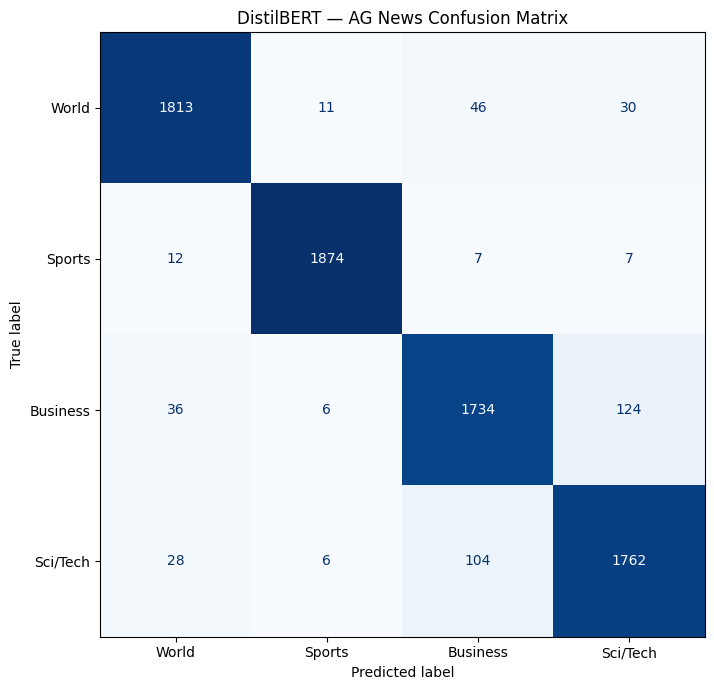

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_labels))
)

cm_df = pd.DataFrame(
    cm,
    index=label_names,
    columns=label_names
)

print("Confusion Matrix:")
display(cm_df)

cm_df.to_csv(
    os.path.join(OUTPUT_DIR, "confusion_matrix.csv")
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("DistilBERT — AG News Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "confusion_matrix.png"),
    dpi=150
)

plt.show()

### Cell 18 - Misclassification error analysis

In [ ]:
error_df = pd.DataFrame({
    "text": test_dataset["text"],
    "true_label_id": y_true,
    "predicted_label_id": y_pred
})

error_df["true_label"] = error_df["true_label_id"].map(id2label)
error_df["predicted_label"] = (
    error_df["predicted_label_id"].map(id2label)
)

probabilities = torch.softmax(
    torch.tensor(test_logits),
    dim=-1
).numpy()

error_df["predicted_confidence"] = probabilities.max(axis=1)

error_df["is_correct"] = (
    error_df["true_label_id"] ==
    error_df["predicted_label_id"]
)

misclassified_df = error_df[
    ~error_df["is_correct"]
].copy()

misclassified_df = misclassified_df.sort_values(
    "predicted_confidence",
    ascending=False
)

print("Total test samples:", len(error_df))
print("Correct predictions:", int(error_df["is_correct"].sum()))
print("Incorrect predictions:", len(misclassified_df))

print("\nMisclassified examples:")
display(
    misclassified_df[
        [
            "text",
            "true_label",
            "predicted_label",
            "predicted_confidence"
        ]
    ].head(20)
)

misclassified_df.to_csv(
    os.path.join(OUTPUT_DIR, "misclassified_examples.csv"),
    index=False
)

error_df.to_csv(
    os.path.join(OUTPUT_DIR, "all_test_predictions.csv"),
    index=False
)

Total test samples: 7600
Correct predictions: 7183
Incorrect predictions: 417

Misclassified examples:


,text,true_label,predicted_label,predicted_confidence
912,Bryant Makes First Appearance at Trial (AP) AP...,Sci/Tech,Sports,0.999756
2126,Bush Scraps Most U.S. Sanctions on Libya (Reut...,Sci/Tech,World,0.999731
6185,Special to ESPN.com It #39;s the age old quest...,Business,Sports,0.999680
311,"French Take Gold, Bronze in Single Kayak ATHEN...",Sports,World,0.999671
7228,Indonesian diplomats asked to help improve RI ...,Business,World,0.999634
1269,Philippines mourns dead in Russian school sieg...,Sci/Tech,World,0.999613
5127,Another homicide in Holland It is a sad day. ...,Sci/Tech,World,0.999588
1197,World briefs LONDON - A man wielding a machete...,Business,World,0.999553
5902,Press review 0850CET--The seizure of fake Nike...,Sci/Tech,Sports,0.999534
4815,"Blame player, not game It was like nothing you...",Sci/Tech,Sports,0.999473


### Cell 19 - Error analysis by class

Class-wise error analysis:


,misclassified_count,total_samples,error_rate
true_label,,,
World,87,1900,0.045789
Sports,26,1900,0.013684
Business,166,1900,0.087368
Sci/Tech,138,1900,0.072632


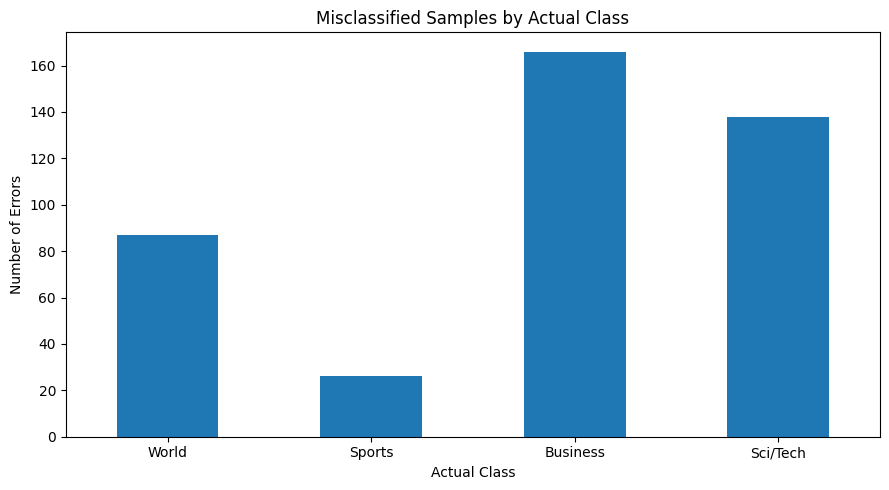

In [ ]:
class_errors = (
    misclassified_df["true_label"]
    .value_counts()
    .reindex(label_names, fill_value=0)
)

class_error_df = class_errors.rename(
    "misclassified_count"
).to_frame()

class_error_df["total_samples"] = (
    pd.Series(y_true)
    .map(id2label)
    .value_counts()
    .reindex(label_names)
)

class_error_df["error_rate"] = (
    class_error_df["misclassified_count"] /
    class_error_df["total_samples"]
)

print("Class-wise error analysis:")
display(class_error_df)

class_error_df.to_csv(
    os.path.join(OUTPUT_DIR, "class_error_analysis.csv")
)

plt.figure(figsize=(9, 5))
class_error_df["misclassified_count"].plot(kind="bar")

plt.title("Misclassified Samples by Actual Class")
plt.xlabel("Actual Class")
plt.ylabel("Number of Errors")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(OUTPUT_DIR, "class_error_analysis.png"),
    dpi=150
)

plt.show()

### Cell 20 - Save the fine-tuned model

In [ ]:
FINAL_MODEL_DIR = os.path.join(
    OUTPUT_DIR,
    "fine_tuned_distilbert"
)

trainer.save_model(FINAL_MODEL_DIR)
tokenizer.save_pretrained(FINAL_MODEL_DIR)

print("Model saved to:", FINAL_MODEL_DIR)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to: project11_outputs/fine_tuned_distilbert


### Cell 21 - Custom text predictions

In [ ]:
custom_texts = [
    "The United Nations discussed a new international agreement.",
    "The team won the championship after an exciting final.",
    "The stock market rose following strong company earnings.",
    "Researchers announced a new breakthrough in artificial intelligence."
]

custom_inputs = tokenizer(
    custom_texts,
    padding=True,
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt"
)

device = trainer.model.device

custom_inputs = {
    key: value.to(device)
    for key, value in custom_inputs.items()
}

trainer.model.eval()

with torch.no_grad():
    custom_outputs = trainer.model(**custom_inputs)

custom_probs = torch.softmax(
    custom_outputs.logits,
    dim=-1
).cpu().numpy()

custom_predictions = np.argmax(
    custom_probs,
    axis=1
)

custom_df = pd.DataFrame({
    "text": custom_texts,
    "predicted_category": [
        id2label[int(i)] for i in custom_predictions
    ],
    "confidence": custom_probs.max(axis=1)
})

print("Custom prediction results:")
display(custom_df)

custom_df.to_csv(
    os.path.join(OUTPUT_DIR, "custom_predictions.csv"),
    index=False
)

Custom prediction results:


,text,predicted_category,confidence
0,The United Nations discussed a new internation...,World,0.988962
1,The team won the championship after an excitin...,Sports,0.965364
2,The stock market rose following strong company...,Business,0.998290
3,Researchers announced a new breakthrough in ar...,Sci/Tech,0.985987


### Cell 22 - Save project summary

In [ ]:
summary = {
    "project": "Project 11: Transformer-Based Text Classification",
    "dataset": "AG News",
    "model": MODEL_NAME,
    "task": "Multiclass news classification",
    "classes": label_names,

    "dataset_sizes": {
        "training": len(train_dataset),
        "validation": len(validation_dataset),
        "test": len(test_dataset)
    },

    "configuration": {
        "max_length": MAX_LENGTH,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "maximum_epochs": EPOCHS,
        "random_seed": SEED,
        "gpu_available": torch.cuda.is_available(),
        "gpu_name": (
            torch.cuda.get_device_name(0)
            if torch.cuda.is_available()
            else None
        )
    },

    "best_checkpoint": trainer.state.best_model_checkpoint,
    "best_validation_macro_f1": (
        float(trainer.state.best_metric)
        if trainer.state.best_metric is not None
        else None
    ),

    "test_metrics": metrics_dict,

    "misclassified_samples": int(len(misclassified_df))
}

with open(
    os.path.join(OUTPUT_DIR, "project_summary.json"),
    "w"
) as f:
    json.dump(summary, f, indent=4)

print(json.dumps(summary, indent=4))

{
    "project": "Project 11: Transformer-Based Text Classification",
    "dataset": "AG News",
    "model": "distilbert/distilbert-base-uncased",
    "task": "Multiclass news classification",
    "classes": [
        "World",
        "Sports",
        "Business",
        "Sci/Tech"
    ],
    "dataset_sizes": {
        "training": 108000,
        "validation": 12000,
        "test": 7600
    },
    "configuration": {
        "max_length": 128,
        "batch_size": 16,
        "learning_rate": 2e-05,
        "maximum_epochs": 3,
        "random_seed": 42,
        "gpu_available": true,
        "gpu_name": "Tesla T4"
    },
    "best_checkpoint": "project11_outputs/best_checkpoint/checkpoint-20250",
    "best_validation_macro_f1": 0.9455511940729968,
    "test_metrics": {
        "test_loss": 0.22405922412872314,
        "test_accuracy": 0.9451315789473684,
        "test_macro_precision": 0.9452236155146334,
        "test_macro_recall": 0.9451315789473684,
        "test_macro_f1": 0.94

### Cell 23 - Verify generated files

In [ ]:
print("Generated project files:\n")

for root, dirs, files in os.walk(OUTPUT_DIR):
    for file in sorted(files):
        path = os.path.join(root, file)
        size_mb = os.path.getsize(path) / (1024 * 1024)

        print(f"{path} — {size_mb:.2f} MB")

Generated project files:

project11_outputs/all_test_predictions.csv — 1.98 MB
project11_outputs/class_distribution.csv — 0.00 MB
project11_outputs/class_distribution.png — 0.04 MB
project11_outputs/class_error_analysis.csv — 0.00 MB
project11_outputs/class_error_analysis.png — 0.04 MB
project11_outputs/classification_report.csv — 0.00 MB
project11_outputs/confusion_matrix.csv — 0.00 MB
project11_outputs/confusion_matrix.png — 0.05 MB
project11_outputs/custom_predictions.csv — 0.00 MB
project11_outputs/misclassified_examples.csv — 0.10 MB
project11_outputs/project_summary.json — 0.00 MB
project11_outputs/test_metrics.json — 0.00 MB
project11_outputs/training_curves.png — 0.09 MB
project11_outputs/training_history.csv — 0.00 MB
project11_outputs/fine_tuned_distilbert/config.json — 0.00 MB
project11_outputs/fine_tuned_distilbert/model.safetensors — 255.43 MB
project11_outputs/fine_tuned_distilbert/tokenizer.json — 0.68 MB
project11_outputs/fine_tuned_distilbert/tokenizer_config.json — 0.

### Cell 24 - Create ZIP archive

In [ ]:
zip_path = shutil.make_archive(
    "project11_outputs",
    "zip",
    OUTPUT_DIR
)

print("ZIP archive created:", zip_path)

from google.colab import files
files.download(zip_path)

ZIP archive created: /content/project11_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>